Step 1: Open Colab and load the penguins

https://github.com/sihsieh65-tech/cs82a-portfolio/tree/main/Module8

In [8]:
import pandas as pd

In [9]:
df = pd.read_csv('/penguins.csv')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


Step 2: Establish ground truth by hand, no AI

In [10]:
df.shape

(344, 8)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 21.6+ KB


In [12]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [13]:
df['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


Step 3: Prompt the AI (and log it)

Prompt log:

I used google gemini

I used the following prompt:

"You are helping with exploratory data analysis.

My CSV has columns: RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object
 1   island             344 non-null    object
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), object(3)

Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare [numeric column] across [category column],
(3) produce one labeled chart.
Explain each step in comments."

Step 4: Run the AI’s code

--- Missing Data Summary ---
                   Missing Count  Missing Percentage (%)
bill_length_mm                 2                    0.58
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
body_mass_g                    2                    0.58
sex                           11                    3.20


--- Summary Statistics of body_mass_g by species ---
           count     mean  median     std     min     max
species                                                  
Adelie       151  3700.66  3700.0  458.57  2850.0  4775.0
Chinstrap     68  3733.09  3700.0  384.34  2700.0  4800.0
Gentoo       123  5076.02  5000.0  504.12  3950.0  6300.0




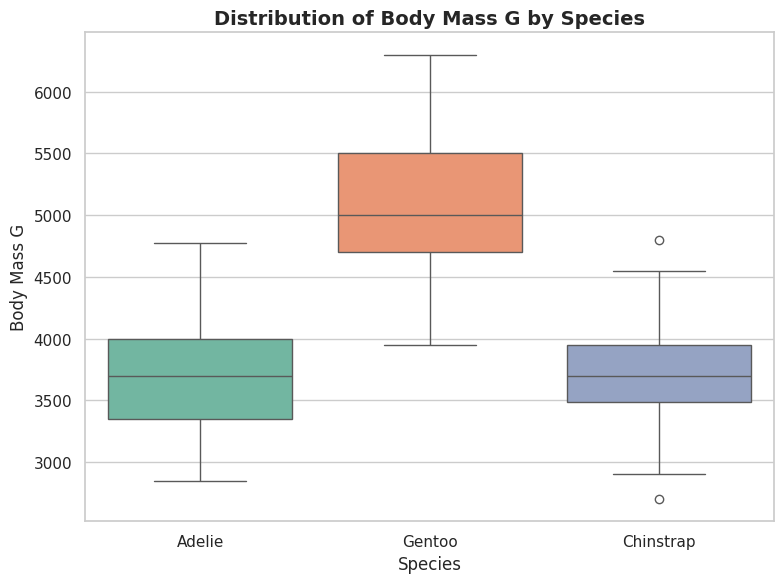

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset (replace 'penguins.csv' with your actual file path)
df = pd.read_csv("penguins.csv")

# ---------------------------------------------------------------------------
# (1) Summarize missing data
# ---------------------------------------------------------------------------
# Calculate total missing values and their percentage per column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

# Create a clean summary DataFrame
missing_summary = pd.DataFrame(
    {"Missing Count": missing_count, "Missing Percentage (%)": missing_percent}
)

# Filter to display only columns that contain missing data
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
print("--- Missing Data Summary ---")
print(missing_summary)
print("\n")

# ---------------------------------------------------------------------------
# (2) Compare [numeric column] across [category column]
# ---------------------------------------------------------------------------
# Defining variables for comparison (e.g., body mass across species)
numeric_col = "body_mass_g"
category_col = "species"

# Compute key descriptive statistics grouped by the categorical column
comparison_summary = (
    df.groupby(category_col)[numeric_col]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(f"--- Summary Statistics of {numeric_col} by {category_col} ---")
print(comparison_summary)
print("\n")

# ---------------------------------------------------------------------------
# (3) Produce one labeled chart
# ---------------------------------------------------------------------------
# Set visual style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# Generate a boxplot to compare distributions visually
sns.boxplot(
    data=df,
    x=category_col,
    y=numeric_col,
    palette="Set2",
    hue=category_col,
    legend=False,
)

# Add clear labels, title, and clean layout
plt.title(
    f"Distribution of {numeric_col.replace('_', ' ').title()} by {category_col.title()}",
    fontsize=14,
    weight="bold",
)
plt.xlabel(category_col.replace("_", " ").title(), fontsize=12)
plt.ylabel(numeric_col.replace("_", " ").title(), fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

--- Missing Data Summary ---
                   Missing Count  Missing Percentage (%)
bill_length_mm                 2                    0.58
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
body_mass_g                    2                    0.58
sex                           11                    3.20


--- Summary Statistics of flipper_length_mm by species ---
           count    mean  median   std    min    max
species                                             
Adelie       151  189.95   190.0  6.54  172.0  210.0
Chinstrap     68  195.82   196.0  7.13  178.0  212.0
Gentoo       123  217.19   216.0  6.48  203.0  231.0




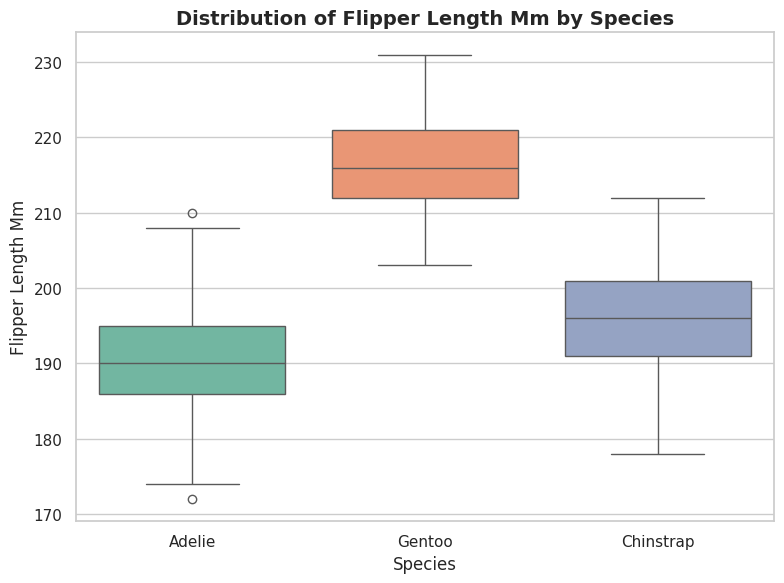

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset (replace 'penguins.csv' with your actual file path)
df = pd.read_csv("penguins.csv")

# ---------------------------------------------------------------------------
# (1) Summarize missing data
# ---------------------------------------------------------------------------
# Calculate total missing values and their percentage per column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

# Create a clean summary DataFrame
missing_summary = pd.DataFrame(
    {"Missing Count": missing_count, "Missing Percentage (%)": missing_percent}
)

# Filter to display only columns that contain missing data
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
print("--- Missing Data Summary ---")
print(missing_summary)
print("\n")

# ---------------------------------------------------------------------------
# (2) Compare [numeric column] across [category column]
# ---------------------------------------------------------------------------
# Defining variables for comparison (e.g., body mass across species)
numeric_col = "flipper_length_mm"
category_col = "species"

# Compute key descriptive statistics grouped by the categorical column
comparison_summary = (
    df.groupby(category_col)[numeric_col]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(f"--- Summary Statistics of {numeric_col} by {category_col} ---")
print(comparison_summary)
print("\n")

# ---------------------------------------------------------------------------
# (3) Produce one labeled chart
# ---------------------------------------------------------------------------
# Set visual style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 6))

# Generate a boxplot to compare distributions visually
sns.boxplot(
    data=df,
    x=category_col,
    y=numeric_col,
    palette="Set2",
    hue=category_col,
    legend=False,
)

# Add clear labels, title, and clean layout
plt.title(
    f"Distribution of {numeric_col.replace('_', ' ').title()} by {category_col.title()}",
    fontsize=14,
    weight="bold",
)
plt.xlabel(category_col.replace("_", " ").title(), fontsize=12)
plt.ylabel(numeric_col.replace("_", " ").title(), fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

Step 5: The verification checkpoint

In [16]:
df.groupby("species")["body_mass_g"].mean()

,body_mass_g
species,
Adelie,3700.662252
Chinstrap,3733.088235
Gentoo,5076.016260


In [17]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


Both the standard method of using df.groupby and the ai supplied code seem to agree. This indicates that both treated the missing values the same way. Comparing to the table in step 2 it appears that the values were dropped as the AI output showed that 151 Adelie, 68 Chinstrap, and 123 Gentoo penguins were assessed but the original count had 152 Adelie, 68 Chinstrap, and 124 Gentoo penguins.

Step 6: One follow-up, one judgment

Prompt log:

My follow-up was "Can you repeat this analysis but also subdivide each species by sex"

--- Missing Data Summary ---
                   Missing Count  Missing Percentage (%)
bill_length_mm                 2                    0.58
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
body_mass_g                    2                    0.58
sex                           11                    3.20


--- Summary Statistics of body_mass_g by species and sex ---
                  count     mean  median     std     min     max
species   sex                                                   
Adelie    female     73  3368.84  3400.0  269.38  2850.0  3900.0
          male       73  4043.49  4000.0  346.81  3325.0  4775.0
Chinstrap female     34  3527.21  3550.0  285.33  2700.0  4150.0
          male       34  3938.97  3950.0  362.14  3250.0  4800.0
Gentoo    female     58  4679.74  4700.0  281.58  3950.0  5200.0
          male       61  5484.84  5500.0  313.16  4750.0  6300.0




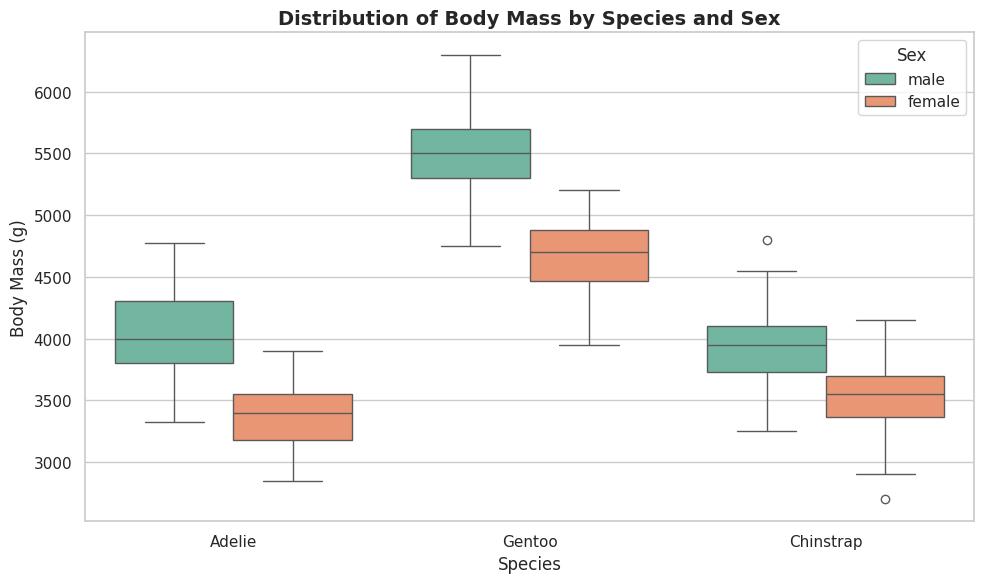

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset (replace 'penguins.csv' with your actual file path)
df = pd.read_csv("penguins.csv")

# ---------------------------------------------------------------------------
# (1) Summarize missing data (including sex breakdowns)
# ---------------------------------------------------------------------------
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame(
    {"Missing Count": missing_count, "Missing Percentage (%)": missing_percent}
)
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

print("--- Missing Data Summary ---")
print(missing_summary)
print("\n")

# ---------------------------------------------------------------------------
# (2) Compare numeric column across species AND sex
# ---------------------------------------------------------------------------
numeric_col = "body_mass_g"
category_cols = ["species", "sex"]

# Group by both species and sex to compute multi-level descriptive statistics
comparison_summary = (
    df.groupby(category_cols)[numeric_col]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(
    f"--- Summary Statistics of {numeric_col} by {category_cols[0]} and {category_cols[1]} ---"
)
print(comparison_summary)
print("\n")

# ---------------------------------------------------------------------------
# (3) Produce one labeled chart (Grouped Boxplot with Hue)
# ---------------------------------------------------------------------------
# Set visual style and figure size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Generate a grouped boxplot splitting species by sex using 'hue'
sns.boxplot(
    data=df,
    x="species",
    y="body_mass_g",
    hue="sex",
    palette="Set2",
)

# Add clear labels, title, and legend formatting
plt.title(
    "Distribution of Body Mass by Species and Sex",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Species", fontsize=12)
plt.ylabel("Body Mass (g)", fontsize=12)
plt.legend(title="Sex", loc="upper right")

# Display the plot
plt.tight_layout()
plt.show()

In [19]:
df.groupby(["species","sex"])["body_mass_g"].mean()

species    sex   
Adelie     female    3368.835616
           male      4043.493151
Chinstrap  female    3527.205882
           male      3938.970588
Gentoo     female    4679.741379
           male      5484.836066
Name: body_mass_g, dtype: float64

The code seems reasonable as it is mostly identical to the previous one but simply adds another parameter to group by which is what I would expect to see.

Step 7: Your original insight, no AI

In [20]:
df[['island','species']].value_counts()

island     species  
Biscoe     Gentoo       124
Dream      Chinstrap     68
           Adelie        56
Torgersen  Adelie        52
Biscoe     Adelie        44
Name: count, dtype: int64

Adelie penguins are the only species shown to inhabit all three islands. Despite this the variation in their weight is not notably different than the variation in the weights of the other species.  

Step 8: Privacy reflection (markdown cell)
This dataset is public animals. Name one dataset from your own life or work you must NEVER paste into a public AI tool, and what you would do instead (anonymize, aggregate, or use an approved internal tool). 2–3 sentences.

In my line of work I have access to workers' compensation data. I would always remove any personally identifying information before presenting my findings. Alternatively I would aggregate my data so that individual information is concealed.

Step 9: Reproducibility check and portfolio finish